# Fase C — Modelos Predictivos
**Problema principal (clasificación):** predecir `ALTO_RIESGO_DESERCION` (deserción > 5 %) de un municipio-año.
**Problema complementario (regresión):** estimar la tasa de `DESERCIÓN` (%) — permite la gráfica *predicho vs. real* que pide la Fase D.
**No supervisado:** segmentar los municipios (corte 2024) por su perfil educativo con K-Means.

Reglas aplicadas (guía + checklist del profesor): **un único `train_test_split` 80/20 con `random_state=42` y `stratify`** para todos los modelos · **imputación (KNN + mediana) y escalado dentro de un `Pipeline`**, ajustados solo con train · métricas siempre **en test** · `random_state=42` en todos los modelos · además, **validación temporal** (entrenar con años pasados y probar en años futuros) para todos los modelos.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from time import perf_counter
from sklearn.base import clone
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay, mean_squared_error, mean_absolute_error, r2_score,
                             silhouette_score, davies_bouldin_score)

sns.set_theme(style="whitegrid")
os.makedirs("figuras", exist_ok=True); os.makedirs("resultados", exist_ok=True)
def guardar(nombre):
    plt.savefig(f"figuras/{nombre}.png", dpi=130, bbox_inches="tight")
SEED = 42

df = pd.read_parquet("datos_limpios.parquet")
print(df.shape)

(15558, 60)


## 1. Selección de variables y control de *leakage*
Se **excluyen** de las features:
- `APROBACIÓN*`: por construcción `APROBACIÓN + REPROBACIÓN + DESERCIÓN = 100 %` (verificado abajo). Con aprobación y reprobación el modelo "calcularía" la deserción en lugar de predecirla.
- `DESERCIÓN_<nivel>`: son los componentes del propio objetivo.
- `TASA_MATRICULACIÓN_5_16`: casi idéntica a `COBERTURA_NETA` (r = 0.90 en la Fase A): redundante.
- Identificadores (municipio, códigos, ETC) y las versiones de texto de las categóricas (ya codificadas).

Se **incluye** `DESERCIÓN_AÑO_ANTERIOR` (historial del municipio, conocido al momento de predecir). Por eso el modelado supervisado usa 2012–2024 (los registros sin año anterior se dejan fuera). Para cada variable sesgada se usa su versión `LOG_` de la Fase B.

In [2]:
print("Mediana de APROBACIÓN + REPROBACIÓN + DESERCIÓN:", (df["APROBACIÓN"] + df["REPROBACIÓN"] + df["DESERCIÓN"]).median())

BASE = [c for c in df.columns if c.startswith(("COBERTURA", "REPROBACIÓN", "REPITENCIA"))] + ["POBLACIÓN_5_16"]
FEATURES = (["AÑO", "TAMAÑO_MUNICIPIO_ORD", "DESERCIÓN_AÑO_ANTERIOR"] + [f"LOG_{c}" if f"LOG_{c}" in df.columns else c for c in BASE]
            + [c for c in df.columns if c.startswith(("REGION_", "TIPO_ETC_"))])
dm = df.dropna(subset=["DESERCIÓN_AÑO_ANTERIOR"]).reset_index(drop=True)
print("Registros para modelar:", len(dm), "de", len(df))
X = dm[FEATURES]
y = dm["ALTO_RIESGO_DESERCION"]
y_reg = dm["DESERCIÓN"]
print(len(FEATURES), "features:", FEATURES)

Mediana de APROBACIÓN + REPROBACIÓN + DESERCIÓN: 100.0
Registros para modelar: 14387 de 15558
30 features: ['AÑO', 'TAMAÑO_MUNICIPIO_ORD', 'DESERCIÓN_AÑO_ANTERIOR', 'COBERTURA_NETA', 'COBERTURA_NETA_TRANSICIÓN', 'COBERTURA_NETA_PRIMARIA', 'COBERTURA_NETA_SECUNDARIA', 'COBERTURA_NETA_MEDIA', 'COBERTURA_BRUTA', 'COBERTURA_BRUTA_TRANSICIÓN', 'COBERTURA_BRUTA_PRIMARIA', 'COBERTURA_BRUTA_SECUNDARIA', 'COBERTURA_BRUTA_MEDIA', 'REPROBACIÓN', 'LOG_REPROBACIÓN_TRANSICIÓN', 'LOG_REPROBACIÓN_PRIMARIA', 'REPROBACIÓN_SECUNDARIA', 'LOG_REPROBACIÓN_MEDIA', 'LOG_REPITENCIA', 'LOG_REPITENCIA_TRANSICIÓN', 'LOG_REPITENCIA_PRIMARIA', 'LOG_REPITENCIA_SECUNDARIA', 'LOG_REPITENCIA_MEDIA', 'LOG_POBLACIÓN_5_16', 'REGION_Andina', 'REGION_Caribe', 'REGION_Insular', 'REGION_Orinoquía', 'REGION_Pacífica', 'TIPO_ETC_Municipal certificada']


### 1.1 Preprocesamiento reproducible (sin fuga de información)
Los pocos nulos de las features (< 1 % por columna) se imputan **dentro del `Pipeline`**: KNN (k = 5) para las coberturas y la mediana para reprobación/repitencia, tal como se decidió en la Fase B. Como el `Pipeline` se entrena con `fit(X_train)`, **el imputador solo aprende de train** y en test solo aplica `transform`. Lo mismo pasa dentro de cada pliegue de validación cruzada y en la validación temporal.

In [3]:
COB_F = [c for c in FEATURES if c.startswith("COBERTURA")]
MED_F = [c for c in FEATURES if c.startswith(("REPROBACIÓN", "REPITENCIA", "LOG_REPROBACIÓN", "LOG_REPITENCIA"))]
con_nulos = X.columns[X.isna().any()]
assert set(con_nulos) <= set(COB_F + MED_F), "Hay nulos fuera de las columnas que imputa el Pipeline"
print("Columnas con nulos (se imputan en el Pipeline):", len(con_nulos), "| total de celdas nulas:", int(X.isna().sum().sum()))

def prep():
    # Nuevo imputador por modelo: se ajusta con los datos que reciba fit() (solo train)
    return ColumnTransformer([("knn", KNNImputer(n_neighbors=5), COB_F), ("mediana", SimpleImputer(strategy="median"), MED_F)],
                             remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")

Columnas con nulos (se imputan en el Pipeline): 20 | total de celdas nulas: 1219


## 2. Balance del objetivo y split único

In [4]:
print(y.value_counts(normalize=True).round(3))
X_train, X_test, y_train, y_test, yr_train, yr_test = train_test_split(
    X, y, y_reg, test_size=0.2, random_state=SEED, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporción de alto riesgo  train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))

ALTO_RIESGO_DESERCION
0    0.807
1    0.193
Name: proportion, dtype: float64
Train: (11509, 30) | Test: (2878, 30)
Proporción de alto riesgo  train: 0.193  test: 0.193


El objetivo está **desbalanceado (≈ 80 / 20)**. Por eso: (1) se usa `stratify` para conservar la proporción en train y test, (2) se usa `class_weight="balanced"` en los modelos que lo soportan, y (3) la métrica principal de comparación es **F1** (y Recall), no Accuracy: un modelo que diga "nunca hay riesgo" tendría 80 % de accuracy y sería inútil.

## 3. Modelos supervisados de clasificación

In [5]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
modelos = {
    "Baseline (clase mayoritaria)": make_pipeline(prep(), DummyClassifier(strategy="most_frequent")),
    "Regresión logística": make_pipeline(prep(), StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED)),
    "KNN": GridSearchCV(make_pipeline(prep(), StandardScaler(), KNeighborsClassifier()),
                        {"kneighborsclassifier__n_neighbors": [5, 11, 21, 41], "kneighborsclassifier__weights": ["uniform", "distance"]},
                        scoring="f1", cv=cv),
    "Random Forest": make_pipeline(prep(), RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced", n_jobs=-1, random_state=SEED)),
    "Gradient Boosting": make_pipeline(prep(), GradientBoostingClassifier(n_estimators=300, learning_rate=0.1, max_depth=3, random_state=SEED)),
}
filas, probas = [], {}
for nombre, m in modelos.items():
    t0 = perf_counter(); m.fit(X_train, y_train); t = perf_counter() - t0
    pred = m.predict(X_test); probas[nombre] = m.predict_proba(X_test)[:, 1]
    filas.append({"Modelo": nombre, "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred, zero_division=0),
                  "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, probas[nombre]),
                  "Tiempo entrenamiento (s)": t})
print("KNN – mejores hiperparámetros (CV en train):", modelos["KNN"].best_params_)
tabla_clf = pd.DataFrame(filas).set_index("Modelo").round(3)
tabla_clf.to_csv("resultados/metricas_clasificacion.csv")
tabla_clf

KNN – mejores hiperparámetros (CV en train): {'kneighborsclassifier__n_neighbors': 5, 'kneighborsclassifier__weights': 'distance'}


,Accuracy,Precision,Recall,F1,ROC-AUC,Tiempo entrenamiento (s)
Modelo,,,,,,
Baseline (clase mayoritaria),0.807,0.000,0.000,0.000,0.500,0.432
Regresión logística,0.720,0.375,0.674,0.482,0.785,0.523
KNN,0.818,0.551,0.300,0.389,0.741,23.880
Random Forest,0.826,0.578,0.358,0.442,0.802,3.712
Gradient Boosting,0.829,0.610,0.324,0.423,0.804,34.153


**Lectura:** Todos los modelos superan con claridad al baseline (que tiene 80.7 % de accuracy pero F1 = 0, porque nunca detecta un municipio en riesgo). Random Forest y Gradient Boosting tienen la mejor capacidad de ordenar el riesgo (ROC-AUC ≈ 0.80) y la mayor precisión (58–61 %). La regresión logística, gracias a `class_weight="balanced"`, tiene el mayor recall (67 %) a costa de muchas falsas alarmas. Con el umbral por defecto de 0.5 los árboles son conservadores; esto se revisa en las secciones 3.5 y 3.6.

### 3.1 Matrices de confusión (test)

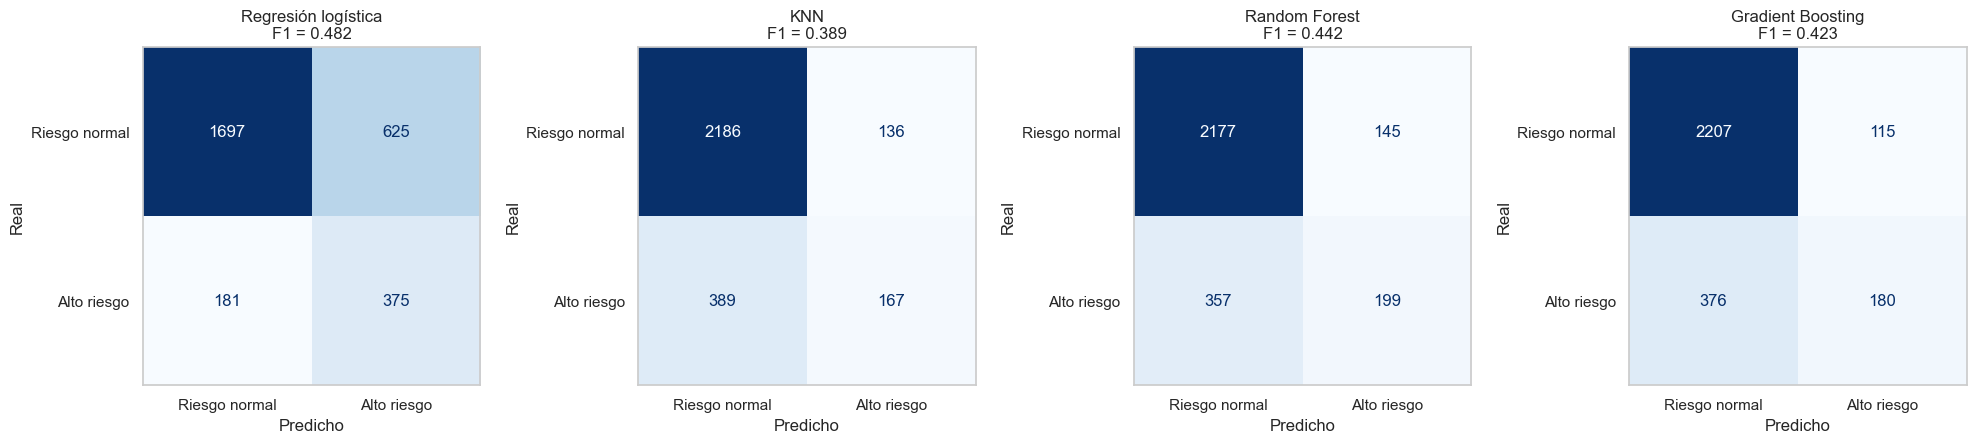

In [6]:
SUP = [m for m in modelos if not m.startswith("Baseline")]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, nombre in zip(axes, SUP):
    ConfusionMatrixDisplay.from_estimator(modelos[nombre], X_test, y_test, display_labels=["Riesgo normal", "Alto riesgo"], cmap="Blues", ax=ax, colorbar=False)
    ax.grid(False); ax.set_title(f"{nombre}\nF1 = {tabla_clf.loc[nombre, 'F1']:.3f}"); ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
plt.tight_layout(); guardar("c_matrices_confusion"); plt.show()

**Insight:** La regresión logística detecta 2 de cada 3 municipios en alto riesgo, pero genera muchos falsos positivos (casi 2 alarmas falsas por cada acierto). Random Forest y Gradient Boosting son más precisos (6 de cada 10 alarmas son correctas), pero con el umbral 0.5 dejan pasar a la mayoría de los municipios en riesgo. Para el Ministerio un falso negativo (no intervenir un municipio que sí abandona) es más costoso que una visita de más, por lo que conviene priorizar el recall.

### 3.2 Curvas ROC (test)

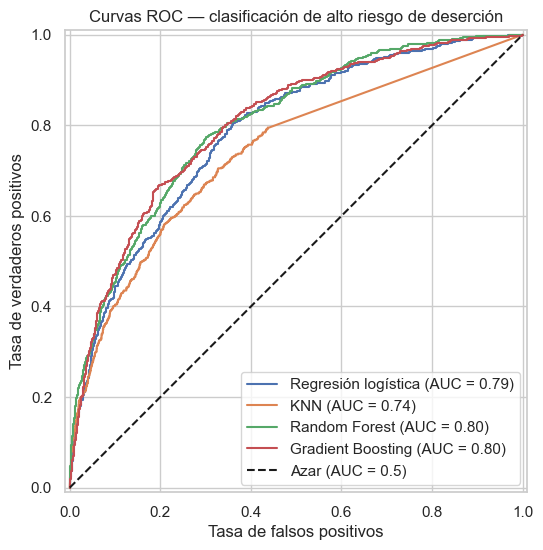

In [7]:
fig, ax = plt.subplots(figsize=(7, 6))
for nombre in SUP:
    RocCurveDisplay.from_predictions(y_test, probas[nombre], name=nombre, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.5)")
ax.set_title("Curvas ROC — clasificación de alto riesgo de deserción"); ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos"); ax.legend(loc="lower right")
guardar("c_roc"); plt.show()

**Insight:** Las curvas de Random Forest y Gradient Boosting dominan casi en todo el rango (AUC ≈ 0.80), seguidas de la regresión logística (0.79) y KNN (0.74). Un AUC de 0.80 significa que, si se toma al azar un municipio en riesgo y otro que no, el modelo le asigna mayor probabilidad al primero el 80 % de las veces: sirve para priorizar a quién visitar primero.

### 3.3 Comparación de métricas

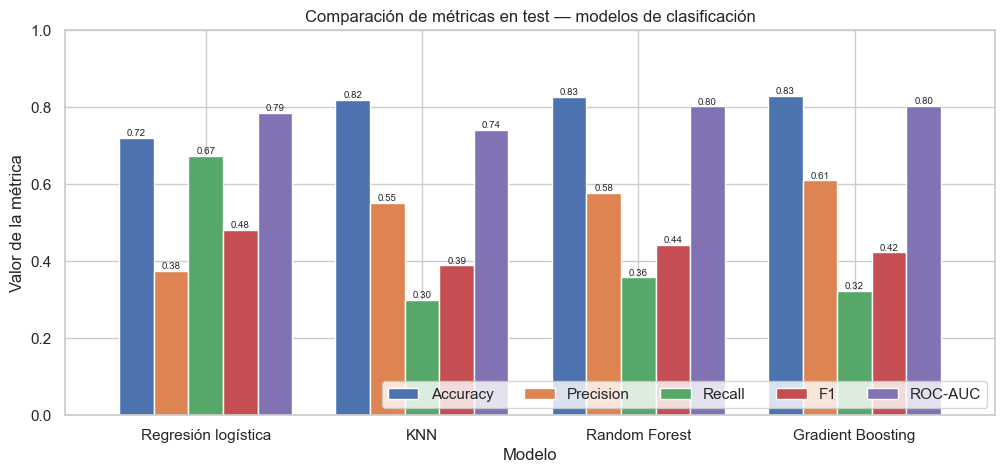

In [8]:
ax = tabla_clf.loc[SUP, ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot.bar(figsize=(12, 5), rot=0, width=.8)
ax.set_title("Comparación de métricas en test — modelos de clasificación"); ax.set_xlabel("Modelo"); ax.set_ylabel("Valor de la métrica"); ax.set_ylim(0, 1)
ax.legend(loc="lower right", ncols=5)
for cont in ax.containers: ax.bar_label(cont, fmt="%.2f", fontsize=7)
guardar("c_comparacion_metricas"); plt.show()

### 3.4 Interpretabilidad: ¿qué variables pesan más? (Random Forest)

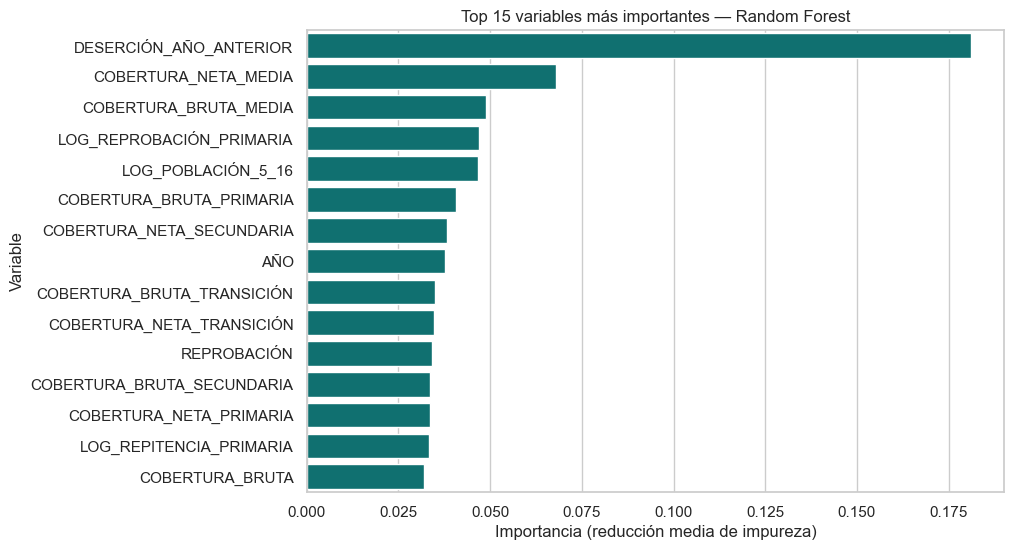

Regresión logística — coeficientes estandarizados más negativos / positivos:
REGION_Andina               -0.55
REGION_Caribe               -0.53
COBERTURA_NETA_PRIMARIA     -0.52
REGION_Pacífica             -0.47
LOG_REPITENCIA              -0.42
COBERTURA_BRUTA              0.48
LOG_REPITENCIA_SECUNDARIA    0.49
LOG_REPROBACIÓN_PRIMARIA     0.57
COBERTURA_NETA               0.61
DESERCIÓN_AÑO_ANTERIOR       0.73


In [9]:
NOMBRES_F = modelos["Random Forest"][0].get_feature_names_out()  # el ColumnTransformer reordena las columnas
imp = pd.Series(modelos["Random Forest"][-1].feature_importances_, index=NOMBRES_F).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(x=imp.values, y=imp.index, color="teal", ax=ax)
ax.set_title("Top 15 variables más importantes — Random Forest"); ax.set_xlabel("Importancia (reducción media de impureza)"); ax.set_ylabel("Variable")
guardar("c_importancia"); plt.show()
coef = pd.Series(modelos["Regresión logística"][-1].coef_[0], index=NOMBRES_F).sort_values()
print("Regresión logística — coeficientes estandarizados más negativos / positivos:")
print(pd.concat([coef.head(5), coef.tail(5)]).round(2).to_string())

**Insight:** El predictor más fuerte, por mucho, es la **deserción del año anterior**: el abandono escolar es persistente y un municipio que estuvo en riesgo tiende a seguir estándolo. Le siguen la **cobertura en educación media** (los municipios donde pocos jóvenes llegan a la media pierden más estudiantes), la reprobación en primaria y el tamaño del municipio. La regresión logística confirma la dirección: más reprobación y repitencia aumentan el riesgo, y pertenecer a las regiones Andina, Caribe o Pacífica (frente a la Amazonía) lo reduce.

### 3.5 Validación temporal de todos los modelos
El split aleatorio mezcla años: un municipio puede tener 2019 y 2021 en train y 2020 en test, así que el modelo puede apoyarse en **patrones compartidos entre años del mismo municipio**. El uso real es otro: con lo que se sabe hoy, anticipar el año siguiente. Por eso se repite la evaluación **separando por tiempo**, sin que ningún dato futuro toque el entrenamiento:

| Bloque | Años | Uso |
|---|---|---|
| Entrenamiento | 2012–2021 | ajustar el modelo (imputador y escalador incluidos) |
| Validación | 2022 | elegir el **umbral de decisión** que maximiza F1 |
| Prueba futura | 2023–2024 | evaluar una sola vez (el modelo se reentrena con 2012–2022 y el umbral queda fijo) |

In [10]:
ent, val, fut = dm["AÑO"] <= 2021, dm["AÑO"] == 2022, dm["AÑO"] >= 2023
print(f"Filas → entrenamiento: {ent.sum()}, validación: {val.sum()}, prueba futura: {fut.sum()}")
print("Proporción de alto riesgo por bloque:", {"2012–2021": round(y[ent].mean(), 3), "2022": round(y[val].mean(), 3), "2023–2024": round(y[fut].mean(), 3)})

umbrales = np.round(np.arange(0.10, 0.90, 0.01), 2)
def mejor_umbral(y_true, p):
    return umbrales[int(np.argmax([f1_score(y_true, p >= u) for u in umbrales]))]

def metricas(y_true, p, u):
    pred = (p >= u).astype(int)
    return [accuracy_score(y_true, pred), precision_score(y_true, pred, zero_division=0), recall_score(y_true, pred), f1_score(y_true, pred), roc_auc_score(y_true, p)]

COLS_M = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
filas, p_fut, u_t = [], {}, {}
for nombre in SUP:
    u_t[nombre] = mejor_umbral(y[val], clone(modelos[nombre]).fit(X[ent], y[ent]).predict_proba(X[val])[:, 1])
    p_fut[nombre] = clone(modelos[nombre]).fit(X[ent | val], y[ent | val]).predict_proba(X[fut])[:, 1]
    filas.append([nombre, u_t[nombre], *metricas(y[fut], p_fut[nombre], u_t[nombre]), *metricas(y[fut], p_fut[nombre], 0.5)[3:4]])
tabla_temp = pd.DataFrame(filas, columns=["Modelo", "Umbral (elegido en 2022)", *COLS_M, "F1 con umbral 0.50"]).set_index("Modelo").round(3)
tabla_temp.to_csv("resultados/metricas_temporal.csv")
tabla_temp

Filas → entrenamiento: 11027, validación: 1120, prueba futura: 2240
Proporción de alto riesgo por bloque: {'2012–2021': np.float64(0.182), '2022': np.float64(0.299), '2023–2024': np.float64(0.194)}


,Umbral (elegido en 2022),Accuracy,Precision,Recall,F1,ROC-AUC,F1 con umbral 0.50
Modelo,,,,,,,
Regresión logística,0.52,0.694,0.376,0.873,0.525,0.846,0.509
KNN,0.14,0.482,0.260,0.906,0.404,0.750,0.449
Random Forest,0.39,0.741,0.414,0.811,0.548,0.834,0.542
Gradient Boosting,0.42,0.794,0.476,0.636,0.544,0.825,0.541


**Lectura:** Separando por tiempo, **los modelos no empeoran: mejoran** (AUC 0.83–0.85 frente a 0.74–0.80 en el split aleatorio). El modelo no dependía de "recordar" a cada municipio entre años vecinos: aprende patrones que se sostienen en años que nunca vio. Random Forest obtiene el mejor F1 (0.55), seguido de cerca por Gradient Boosting (0.54), que es el más preciso (48 %). La regresión logística ordena muy bien (AUC 0.85), pero con su umbral genera más falsas alarmas. KNN es el más débil: su umbral óptimo (0.14) hace que marque casi todo como riesgo.

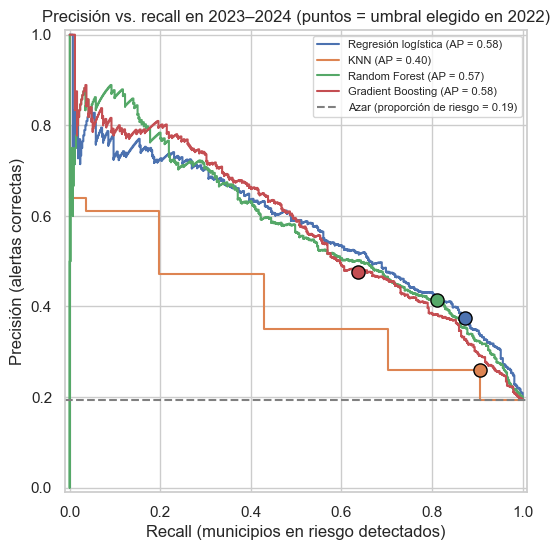

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
for nombre in SUP:
    PrecisionRecallDisplay.from_predictions(y[fut], p_fut[nombre], name=nombre, ax=ax)
for i, nombre in enumerate(SUP):
    pr = (p_fut[nombre] >= u_t[nombre]).astype(int)
    ax.scatter(recall_score(y[fut], pr), precision_score(y[fut], pr), color=f"C{i}", s=90, edgecolor="black", zorder=5)
ax.axhline(y[fut].mean(), color="grey", ls="--", label=f"Azar (proporción de riesgo = {y[fut].mean():.2f})")
ax.set_title("Precisión vs. recall en 2023–2024 (puntos = umbral elegido en 2022)"); ax.set_xlabel("Recall (municipios en riesgo detectados)"); ax.set_ylabel("Precisión (alertas correctas)")
ax.legend(loc="upper right", fontsize=8)
guardar("c_pr_temporal"); plt.show()

**Insight:** Aquí se ve el **costo de detectar más**: cada punto es el umbral elegido en 2022 y cada curva muestra cuánta precisión se pierde al subir el recall. Con Random Forest, el 41 % de las alertas son correctas, **2,1 veces más que alertar al azar** (19 %), y se detecta el 81 % de los municipios que realmente tuvieron deserción alta. Dicho de otra forma, hay unas 1,4 alertas falsas por cada acierto. Parte de esas falsas alarmas se explica porque 2022 fue un año de pico (30 % en riesgo, frente a 19 % en 2023–2024), lo que vuelve al modelo más "alarmista". Si el presupuesto solo alcanza para pocas visitas, se puede subir el umbral (por ejemplo, Gradient Boosting: 48 % de precisión y 64 % de recall); la curva permite elegir ese punto según la capacidad operativa.

### 3.6 Modelo final y su umbral
El umbral del modelo final para el split aleatorio se elige con validación cruzada **dentro de train** (el test no se toca), de modo que ambos protocolos son comparables.

In [12]:
FINAL = "Random Forest"
p_cv = cross_val_predict(clone(modelos[FINAL]), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
U = mejor_umbral(y_train, p_cv)
mejora = pd.DataFrame([metricas(y_test, probas[FINAL], 0.5), metricas(y_test, probas[FINAL], U), tabla_temp.loc[FINAL, COLS_M].tolist()],
                      columns=COLS_M,
                      index=[f"{FINAL} · umbral 0.50 (test aleatorio)", f"{FINAL} · umbral {U:.2f} (test aleatorio)",
                             f"{FINAL} · umbral {u_t[FINAL]:.2f} (entrena 2012–2022, prueba 2023–2024)"]).round(3)
mejora.to_csv("resultados/mejora_modelo_final.csv")
print("Umbral elegido con CV en train:", U)
mejora

Umbral elegido con CV en train: 0.36


,Accuracy,Precision,Recall,F1,ROC-AUC
Random Forest · umbral 0.50 (test aleatorio),0.826,0.578,0.358,0.442,0.802
Random Forest · umbral 0.36 (test aleatorio),0.786,0.458,0.581,0.512,0.802
"Random Forest · umbral 0.39 (entrena 2012–2022, prueba 2023–2024)",0.741,0.414,0.811,0.548,0.834


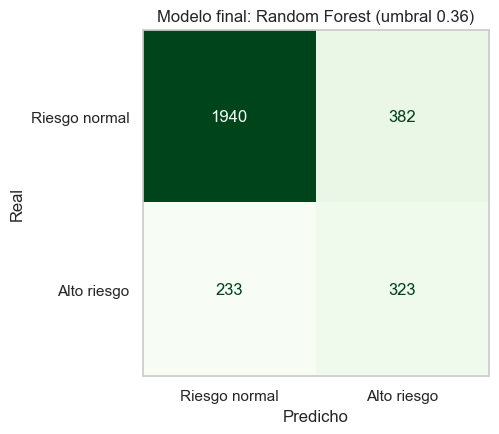

In [13]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, (probas[FINAL] >= U).astype(int), display_labels=["Riesgo normal", "Alto riesgo"], cmap="Greens", ax=ax, colorbar=False)
ax.grid(False); ax.set_title(f"Modelo final: {FINAL} (umbral {U:.2f})"); ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
guardar("c_matriz_final"); plt.show()

**Insight:** En el split aleatorio, bajar el umbral a 0.36 (elegido con CV dentro de train, sin mirar el test) sube el recall del Random Forest de 36 % a 58 % y el F1 de 0.44 a 0.51, el mejor de los modelos. En la validación temporal, con el umbral 0.39 elegido en 2022, alcanza F1 = 0.55, recall = 81 % y AUC = 0.83 en 2023–2024: **sí generaliza a años futuros**. La contrapartida es la precisión (41–46 %): de cada 10 municipios señalados, unos 4 tendrán realmente deserción alta. Es un costo aceptable para una alerta temprana, y el umbral puede subirse si los recursos son limitados (sección 3.5).

## 4. Regresión complementaria: estimar la tasa de deserción
Mismo split (mismas filas de train/test), objetivo continuo `DESERCIÓN`.

In [14]:
regresores = {
    "Regresión lineal": make_pipeline(prep(), StandardScaler(), LinearRegression()),
    "Random Forest Regressor": make_pipeline(prep(), RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=SEED)),
    "Gradient Boosting Regressor": make_pipeline(prep(), GradientBoostingRegressor(n_estimators=300, max_depth=3, random_state=SEED)),
}
filas, preds_reg = [], {}
for nombre, m in regresores.items():
    m.fit(X_train, yr_train); p = preds_reg[nombre] = m.predict(X_test)
    mse = mean_squared_error(yr_test, p)
    filas.append({"Modelo": nombre, "MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(yr_test, p), "R²": r2_score(yr_test, p)})
tabla_reg = pd.DataFrame(filas).set_index("Modelo").round(3)
tabla_reg.to_csv("resultados/metricas_regresion.csv")
tabla_reg

,MSE,RMSE,MAE,R²
Modelo,,,,
Regresión lineal,3.439,1.855,1.317,0.280
Random Forest Regressor,3.202,1.789,1.266,0.329
Gradient Boosting Regressor,3.302,1.817,1.265,0.309


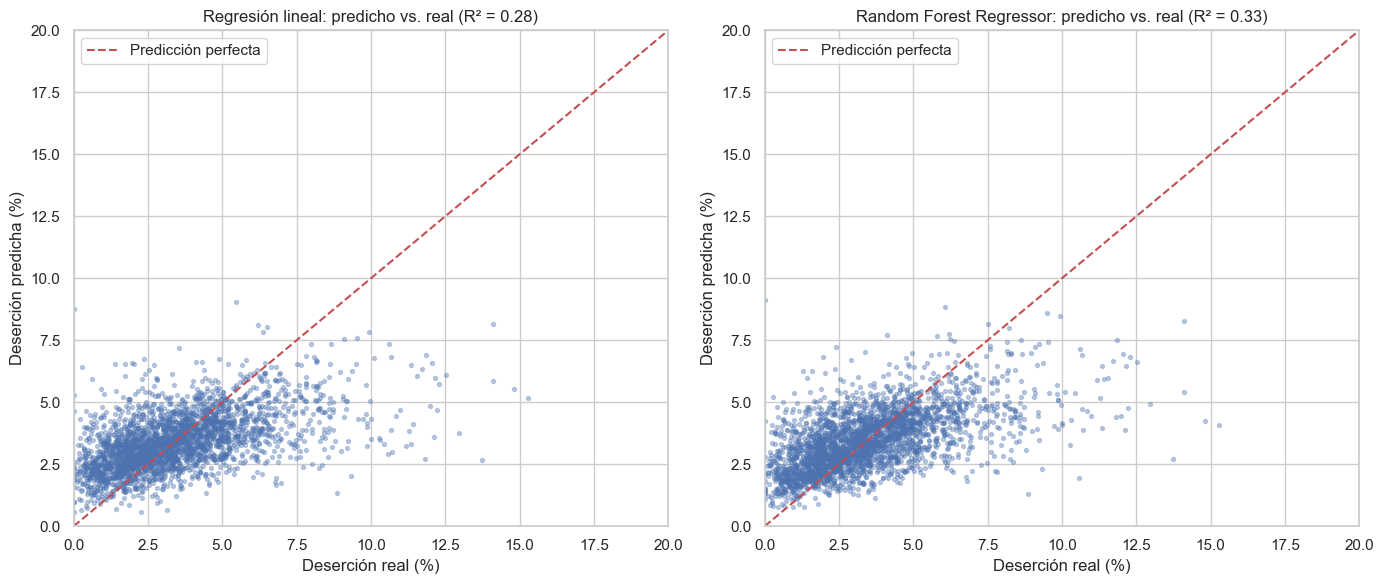

In [15]:
mejor_reg = tabla_reg["R²"].idxmax()
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, nombre in zip(axes, ["Regresión lineal", mejor_reg]):
    ax.scatter(yr_test, preds_reg[nombre], s=8, alpha=.35)
    ax.plot([0, 20], [0, 20], "r--", label="Predicción perfecta")
    ax.set_xlim(0, 20); ax.set_ylim(0, 20)
    ax.set_title(f"{nombre}: predicho vs. real (R² = {tabla_reg.loc[nombre, 'R²']:.2f})"); ax.set_xlabel("Deserción real (%)"); ax.set_ylabel("Deserción predicha (%)"); ax.legend()
plt.tight_layout(); guardar("c_predicho_vs_real"); plt.show()

**Insight:** Estimar el valor exacto de la deserción es más difícil que clasificar el riesgo: el mejor modelo (Random Forest, R² = 0.33, MAE = 1.27 puntos porcentuales) explica un tercio de la variabilidad. En la gráfica se ve que el modelo acierta bien en el rango típico (2–6 %), pero **subestima los casos extremos** (> 10 %), que dependen de factores que no están en el dataset (conflicto, migración, clima, economía local). Por eso el enfoque de clasificación de riesgo es más útil para el negocio.

## 5. Modelo no supervisado: segmentación de municipios (K-Means)
**Unidad:** cada municipio en **2024** (el año más reciente, una fila por municipio, para que un cluster describa municipios y no años).

**Variables elegidas y por qué** (no son las mismas del modelo supervisado):
- `COBERTURA_NETA` y `COBERTURA_NETA_MEDIA` → **acceso**: ¿los niños y jóvenes están en el colegio y llegan a la media?
- `DESERCIÓN`, `REPROBACIÓN`, `LOG_REPITENCIA` → **eficiencia/permanencia**: ¿se quedan y avanzan?
- `LOG_POBLACIÓN_5_16` → **escala** del municipio (las políticas para Bogotá no sirven para Pacoa).

Aquí la deserción **sí** entra, porque no se predice nada: se quiere un perfil completo. Se excluyen las coberturas por nivel (redundantes con las totales) y la región (queremos ver si los perfiles emergen solos, sin dictarles la geografía).

Nulos en las variables de clustering (2024): 0
Municipios 2024: 1121


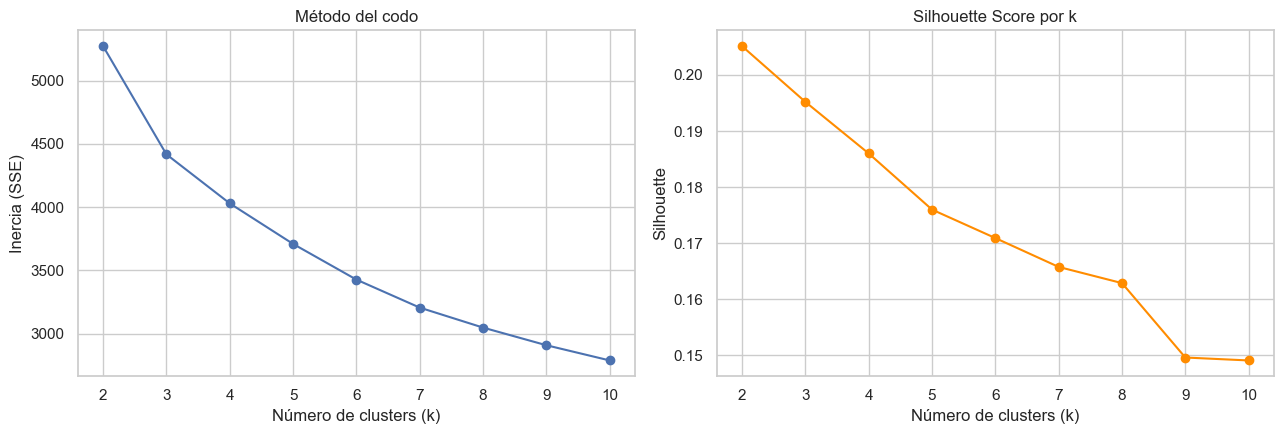

,0,1,2,3,4,5,6,7,8
k,2.000,3.000,4.000,5.000,6.000,7.000,8.000,9.00,10.000
inercia,5273.000,4418.000,4030.000,3710.000,3427.000,3206.000,3048.000,2909.00,2788.000
silhouette,0.205,0.195,0.186,0.176,0.171,0.166,0.163,0.15,0.149


In [16]:
CL_VARS = ["COBERTURA_NETA", "COBERTURA_NETA_MEDIA", "DESERCIÓN", "REPROBACIÓN", "LOG_REPITENCIA", "LOG_POBLACIÓN_5_16"]
d24 = df[df["AÑO"] == 2024].reset_index(drop=True)
# Sin split: en no supervisado no hay test que contaminar; los pocos nulos de 2024 se completan con la mediana de 2024
print("Nulos en las variables de clustering (2024):", int(d24[CL_VARS].isna().sum().sum()))
Z = make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit_transform(d24[CL_VARS])
print("Municipios 2024:", len(d24))

ks = range(2, 11); inercia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    inercia.append(km.inertia_); sil.append(silhouette_score(Z, km.labels_))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ks, inercia, "o-"); axes[0].set_title("Método del codo"); axes[0].set_xlabel("Número de clusters (k)"); axes[0].set_ylabel("Inercia (SSE)")
axes[1].plot(ks, sil, "o-", color="darkorange"); axes[1].set_title("Silhouette Score por k"); axes[1].set_xlabel("Número de clusters (k)"); axes[1].set_ylabel("Silhouette")
plt.tight_layout(); guardar("c_codo_silhouette"); plt.show()
pd.DataFrame({"k": ks, "inercia": np.round(inercia, 0), "silhouette": np.round(sil, 3)}).T

**Elección de k:** El Silhouette más alto se da con k = 2 (0.205), pero dos grupos solo separarían municipios "buenos" y "malos", sin aportar a la focalización. El codo no es marcado; la caída de la inercia se suaviza a partir de k = 4, y el Silhouette con k = 4 (0.186) es casi igual al de k = 2. Se elige **k = 4**, equilibrando calidad matemática e interpretabilidad para el negocio.

In [17]:
K = 4
km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit(Z)
ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Z)
tabla_cl = pd.DataFrame({
    "Silhouette": [silhouette_score(Z, km.labels_), silhouette_score(Z, ward.labels_)],
    "Davies-Bouldin": [davies_bouldin_score(Z, km.labels_), davies_bouldin_score(Z, ward.labels_)],
}, index=[f"K-Means (k={K})", f"Jerárquico Ward (k={K})"]).round(3)
tabla_cl.to_csv("resultados/metricas_clustering.csv")
tabla_cl

,Silhouette,Davies-Bouldin
K-Means (k=4),0.186,1.582
Jerárquico Ward (k=4),0.115,1.809


In [18]:
d24["CLUSTER"] = km.labels_
perfil = d24.groupby("CLUSTER").agg(n_municipios=("MUNICIPIO", "size"), cobertura_neta=("COBERTURA_NETA", "median"),
                                    cobertura_media=("COBERTURA_NETA_MEDIA", "median"), desercion=("DESERCIÓN", "median"),
                                    reprobacion=("REPROBACIÓN", "median"), repitencia=("REPITENCIA", "median"),
                                    poblacion_5_16=("POBLACIÓN_5_16", "median"), pct_alto_riesgo=("ALTO_RIESGO_DESERCION", "mean")).round(2)
perfil

,n_municipios,cobertura_neta,cobertura_media,desercion,reprobacion,repitencia,poblacion_5_16,pct_alto_riesgo
CLUSTER,,,,,,,,
0,216,79.93,38.00,5.62,6.17,9.65,4241.5,0.75
1,390,76.41,46.47,2.28,3.74,6.10,1330.5,0.03
2,303,94.64,54.09,3.29,6.48,8.38,6402.0,0.06
3,212,73.46,31.96,2.99,7.57,11.14,2766.5,0.05


In [19]:
pd.crosstab(d24["CLUSTER"], d24["REGION"], normalize="index").round(2)

REGION,Amazonía,Andina,Caribe,Insular,Orinoquía,Pacífica
CLUSTER,,,,,,
0,0.13,0.37,0.19,0.0,0.12,0.19
1,0.01,0.76,0.05,0.0,0.03,0.15
2,0.00,0.59,0.24,0.0,0.06,0.10
3,0.10,0.35,0.29,0.0,0.02,0.23


In [20]:
for c in range(K):
    print(c, "→", ", ".join(d24.loc[d24["CLUSTER"] == c].nlargest(6, "POBLACIÓN_5_16")["MUNICIPIO"]))

0 → Palmira, Tuluá, Florencia, Dosquebradas, Jamundí, Ciénaga
1 → Yarumal, Alto Baudo, Zarzal, Puerto Berrío, San Agustín, Sonson
2 → Bogotá D.C., Cali, Medellín, Barranquilla, Cartagena, Soacha
3 → Buenaventura, San Andres de Tumaco, Manaure, Cumaribo, Barbacoas, Tuchín


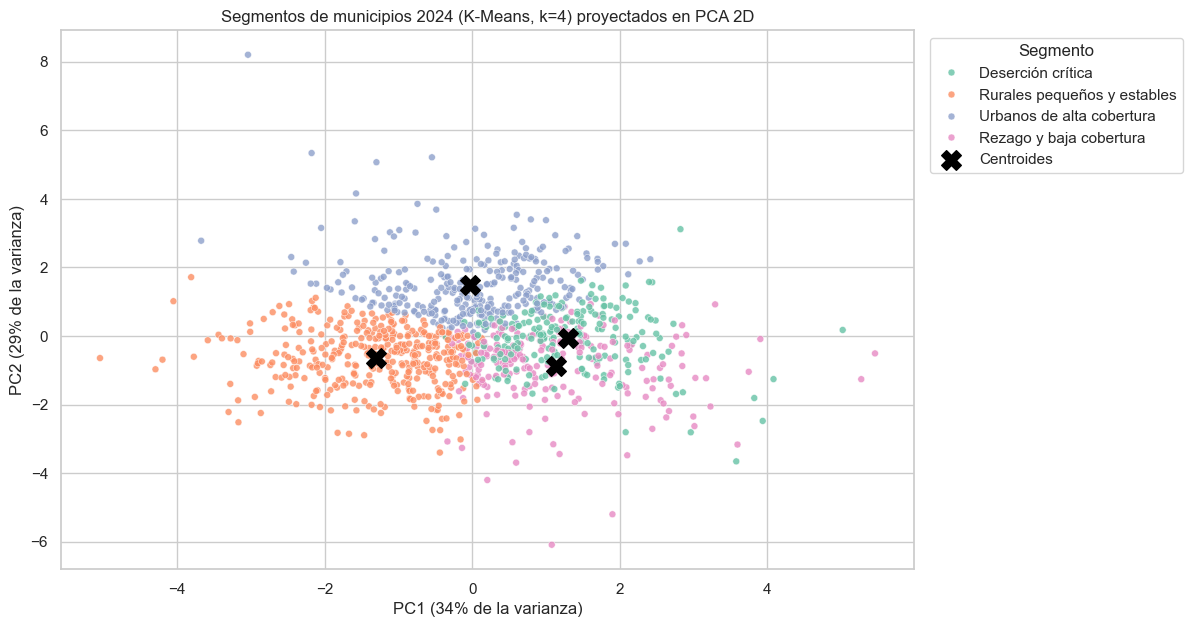

     COBERTURA_NETA  COBERTURA_NETA_MEDIA  DESERCIÓN  REPROBACIÓN  \
PC1           -0.08                 -0.42       0.44         0.44   
PC2            0.69                  0.54       0.06         0.20   

     LOG_REPITENCIA  LOG_POBLACIÓN_5_16  
PC1            0.57                0.34  
PC2            0.03                0.43  


In [21]:
# Nombres asignados tras leer la tabla de perfiles (K-Means con random_state=42 es determinista)
assert perfil["pct_alto_riesgo"].idxmax() == 0 and perfil["cobertura_neta"].idxmax() == 2 and perfil["cobertura_neta"].idxmin() == 3
NOMBRES = {0: "Deserción crítica", 1: "Rurales pequeños y estables", 2: "Urbanos de alta cobertura", 3: "Rezago y baja cobertura"}
d24["SEGMENTO"] = d24["CLUSTER"].map(NOMBRES)
pca = PCA(n_components=2, random_state=SEED).fit(Z); P = pca.transform(Z)
fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=d24["SEGMENTO"], hue_order=list(NOMBRES.values()), palette="Set2", s=25, alpha=.8, ax=ax)
cent = pca.transform(km.cluster_centers_); ax.scatter(cent[:, 0], cent[:, 1], c="black", marker="X", s=200, label="Centroides")
ax.set_title(f"Segmentos de municipios 2024 (K-Means, k={K}) proyectados en PCA 2D")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} de la varianza)")
ax.legend(title="Segmento", bbox_to_anchor=(1.01, 1), loc="upper left")
guardar("c_clusters_pca"); plt.show()
print(pd.DataFrame(pca.components_, columns=CL_VARS, index=["PC1", "PC2"]).round(2))
d24[["CÓDIGO_MUNICIPIO", "MUNICIPIO", "DEPARTAMENTO", "REGION", "CLUSTER", "SEGMENTO"]].to_csv("resultados/segmentos_municipios_2024.csv", index=False)

**Métricas:** K-Means supera al jerárquico Ward en ambas métricas (Silhouette 0.186 frente a 0.115, más alto es mejor; Davies-Bouldin 1.58 frente a 1.81, más bajo es mejor), por eso se adopta K-Means. Un Silhouette cercano a 0.2 indica **grupos con fronteras difusas**: los municipios forman un continuo y no categorías tajantes, algo esperable en datos sociales. Los segmentos sirven como perfiles orientadores, no como cajas rígidas.

## 6. Interpretación de negocio de los segmentos

| Segmento | Municipios | Perfil en palabras | Ejemplos | Acción sugerida |
|---|---|---|---|---|
| **Deserción crítica** | 216 | Municipios intermedios con cobertura aceptable, pero que **pierden a sus estudiantes**: el 75 % está en alto riesgo. | Palmira, Tuluá, Florencia, Dosquebradas, Jamundí | Prioridad 1 para programas de permanencia: alimentación escolar, transporte, seguimiento de ausentismo. |
| **Rurales pequeños y estables** | 390 | Municipios pequeños, casi todos andinos, con baja deserción y baja reprobación. | Yarumal, Zarzal, Sonsón, San Agustín | Mantener; documentar buenas prácticas para replicarlas. |
| **Urbanos de alta cobertura** | 303 | Ciudades y municipios grandes, donde casi todos los niños están matriculados y más jóvenes llegan a la media; deserción moderada. | Bogotá, Cali, Medellín, Barranquilla, Cartagena | Atención focalizada por barrios; el reto es la calidad, no el acceso. |
| **Rezago y baja cobertura** | 212 | Peor acceso (cobertura neta 73 %, solo 32 % en media) y la mayor reprobación y repitencia, pero con deserción **reportada** baja. | Buenaventura, Tumaco, Manaure, Cumaribo, Barbacoas | Ampliar la oferta (sobre todo de media) y recuperar aprendizajes. |

**Respuestas a las preguntas guía:**
- **¿Cuántos clusters? ¿Era lo esperado?** Cuatro. Se esperaba una división urbano/rural; apareció, pero también surgieron dos perfiles problemáticos distintos: uno que *pierde* estudiantes y otro que *no logra incorporarlos*.
- **¿Qué tienen en común?** Ver la columna "Perfil en palabras".
- **Implicaciones prácticas:** el mismo presupuesto no sirve para todos. *Deserción crítica* necesita estrategias de permanencia; *Rezago y baja cobertura* necesita oferta educativa y nivelación.
- **¿Hay un cluster anómalo?** Sí: *Rezago y baja cobertura* tiene la peor situación de acceso, pero una deserción baja. Una explicación plausible es que los jóvenes que abandonarían **ni siquiera se matriculan** (baja cobertura), de modo que la deserción no los registra. También puede haber subregistro en territorios con difícil acceso (La Guajira, el Pacífico, Vichada). La deserción baja aquí **no** es una buena noticia.

## 7. Justificación del modelo final
Se elige **Random Forest** como modelo final (umbral 0.36 en el split aleatorio y 0.39 en el esquema temporal):
- **Precisión:** es el mejor F1 en **ambos** protocolos: 0.51 en el test aleatorio y 0.55 al predecir 2023–2024 con datos hasta 2022 (AUC 0.83). Generaliza a años futuros, que es el uso real.
- **Interpretabilidad:** la importancia de variables es fácil de explicar (historial de deserción, cobertura en media, reprobación). La regresión logística es más transparente y ordena bien en el tiempo (AUC 0.85), pero con su umbral genera más falsas alarmas (precisión 38 %).
- **Velocidad/simplicidad:** entrena en ~2 s, unas 10 veces más rápido que Gradient Boosting, con resultados casi iguales.
- **Sin fuga de información:** imputación, escalado y umbral se ajustan solo con datos de entrenamiento (o de validación, en el esquema temporal).